<a href="https://colab.research.google.com/github/elenarieee/PCD_Assignment03/blob/main/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import numpy as np
import matplotlib.pyplot as plt

DATASET = [
    {"nama": "Beras", "file": "sample_data/rice.jpg",       "object_is_bright": True,  "se_radius": 2},
    {"nama": "Koin",  "file": "sample_data/koin.jpg",       "object_is_bright": True,  "se_radius": 2},
    {"nama": "Apel",  "file": "sample_data/Apple.jpg",      "object_is_bright": False, "se_radius": 2},
]

In [10]:
def load_gray(path):
    raw = plt.imread(path)
    if raw.dtype != np.uint8:
        raw = (raw * 255).astype(np.uint8)
    gray = 0.299 * raw[..., 0] + 0.587 * raw[..., 1] + 0.114 * raw[..., 2]
    return np.clip(np.round(gray), 0, 255).astype(np.uint8)

def otsu_threshold(img):

    hist = np.zeros(256)
    for v in img.ravel():
        hist[v] += 1
    prob = hist / hist.sum()
    levels = np.arange(256)

    best_T, best_sigma = 0, np.inf
    for T in range(1, 256):

        Wb, Wf = prob[:T].sum(), prob[T:].sum()
        if Wb == 0 or Wf == 0:
            continue
        mu_b = (levels[:T] * prob[:T]).sum() / Wb
        mu_f = (levels[T:] * prob[T:]).sum() / Wf
        var_b = (((levels[:T] - mu_b) ** 2) * prob[:T]).sum() / Wb
        var_f = (((levels[T:] - mu_f) ** 2) * prob[T:]).sum() / Wf

        sigma_w = Wb * var_b + Wf * var_f
        if sigma_w < best_sigma:
            best_sigma, best_T = sigma_w, T
    return best_T, hist


def segmentasi(img, T, object_is_bright):

    return (img >= T).astype(np.uint8) if object_is_bright else (img < T).astype(np.uint8)

In [11]:
def se_disk(radius):
    yy, xx = np.mgrid[-radius:radius + 1, -radius:radius + 1]
    return ((yy ** 2 + xx ** 2) <= radius ** 2).astype(np.uint8)

def geseran(img, se):
    h, w = img.shape
    ph, pw = se.shape[0] // 2, se.shape[1] // 2
    padded = np.zeros((h + 2 * ph, w + 2 * pw), dtype=np.uint8)
    padded[ph:ph + h, pw:pw + w] = img
    return [padded[i:i + h, j:j + w]
            for i in range(se.shape[0]) for j in range(se.shape[1]) if se[i, j] == 1]


def erosion(img, se):
    hasil = np.ones_like(img)
    for g in geseran(img, se):
        hasil = hasil & g
    return hasil


def dilation(img, se):
    hasil = np.zeros_like(img)
    for g in geseran(img, se):
        hasil = hasil | g
    return hasil


def opening(img, se):
    return dilation(erosion(img, se), se)


def closing(img, se):
    return erosion(dilation(img, se), se)

In [12]:
def proses_citra(cfg):
    gray = load_gray(cfg["file"])
    T, hist = otsu_threshold(gray)
    seg = segmentasi(gray, T, cfg["object_is_bright"])
    se = se_disk(cfg["se_radius"])

    hasil = [
        ("Otsu saja (tanpa morfologi)", seg),
        ("Erosi", erosion(seg, se)),
        ("Dilasi", dilation(seg, se)),
        ("Opening", opening(seg, se)),
        ("Closing", closing(seg, se)),
        ("Opening lalu Closing", closing(opening(seg, se), se)),
    ]

    print(f"{cfg['nama']} | T Otsu = {T} | SE lingkaran radius {cfg['se_radius']}")
    fig, ax = plt.subplots(2, 4, figsize=(16, 8.5))
    ax[0, 0].imshow(gray, cmap="gray", vmin=0, vmax=255); ax[0, 0].set_title("Grayscale"); ax[0, 0].axis("off")
    for a, (judul, im) in zip([ax[0, 1], ax[0, 2], ax[0, 3], ax[1, 0], ax[1, 1], ax[1, 2]], hasil):
        a.imshow(im, cmap="gray", vmin=0, vmax=1); a.set_title(judul); a.axis("off")
    ax[1, 3].axis("off")      # kotak terakhir dikosongkan
    plt.tight_layout(); plt.show()

    print(f"{'Metode':<30}{'Luas objek (px)':>16}")
    for judul, im in hasil:
        print(f"{judul:<30}{int(im.sum()):>16}")

Beras | T Otsu = 132 | SE lingkaran radius 2


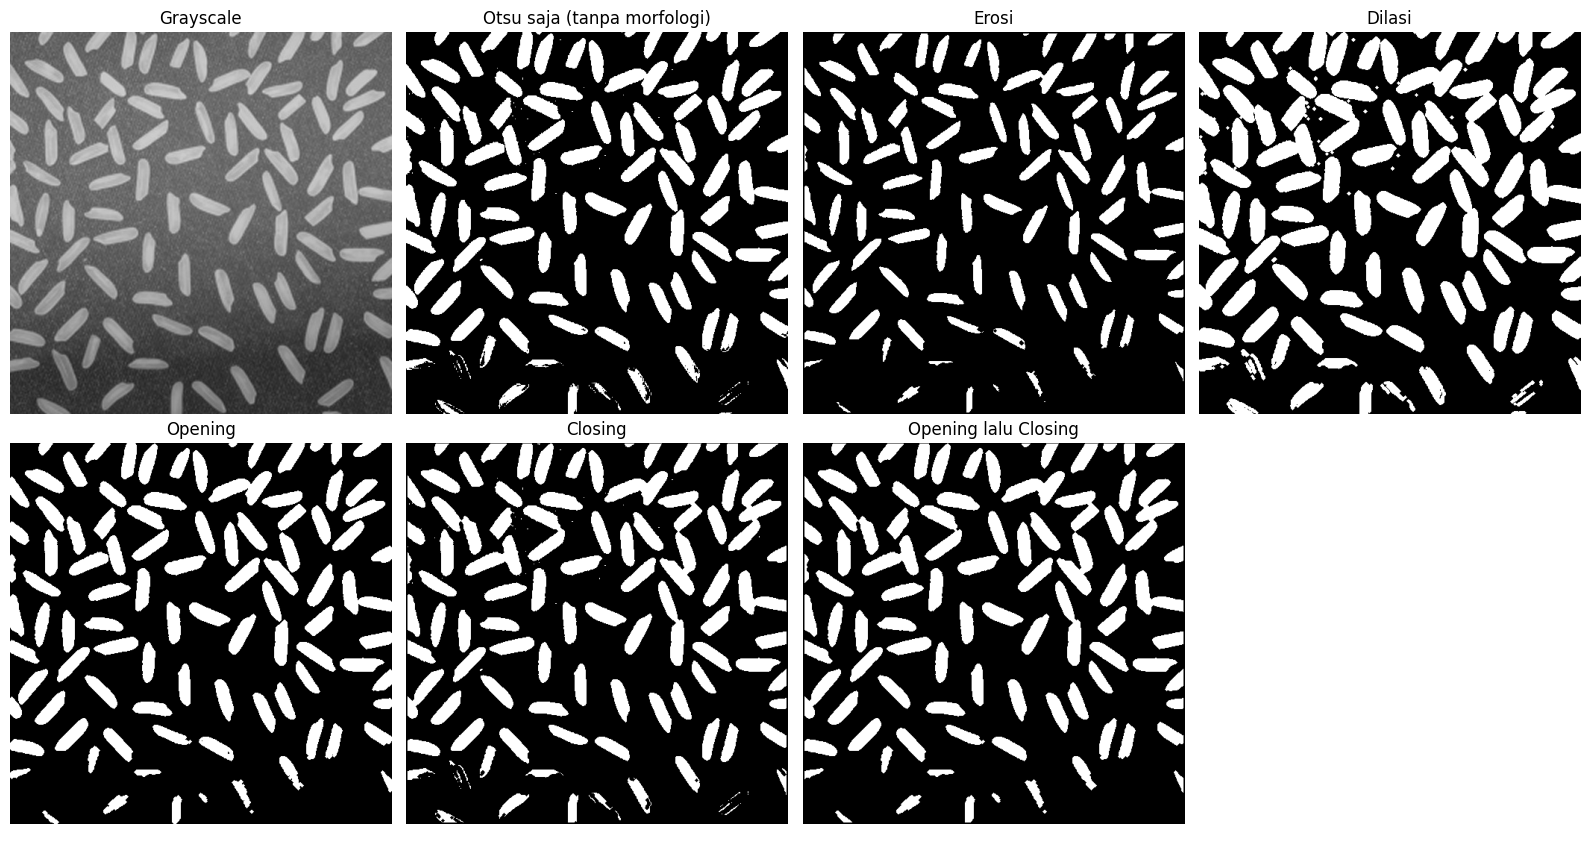

Metode                         Luas objek (px)
Otsu saja (tanpa morfologi)              68164
Erosi                                    47608
Dilasi                                   90582
Opening                                  66667
Closing                                  67844
Opening lalu Closing                     66053


In [13]:
proses_citra(DATASET[0])

Koin | T Otsu = 107 | SE lingkaran radius 2


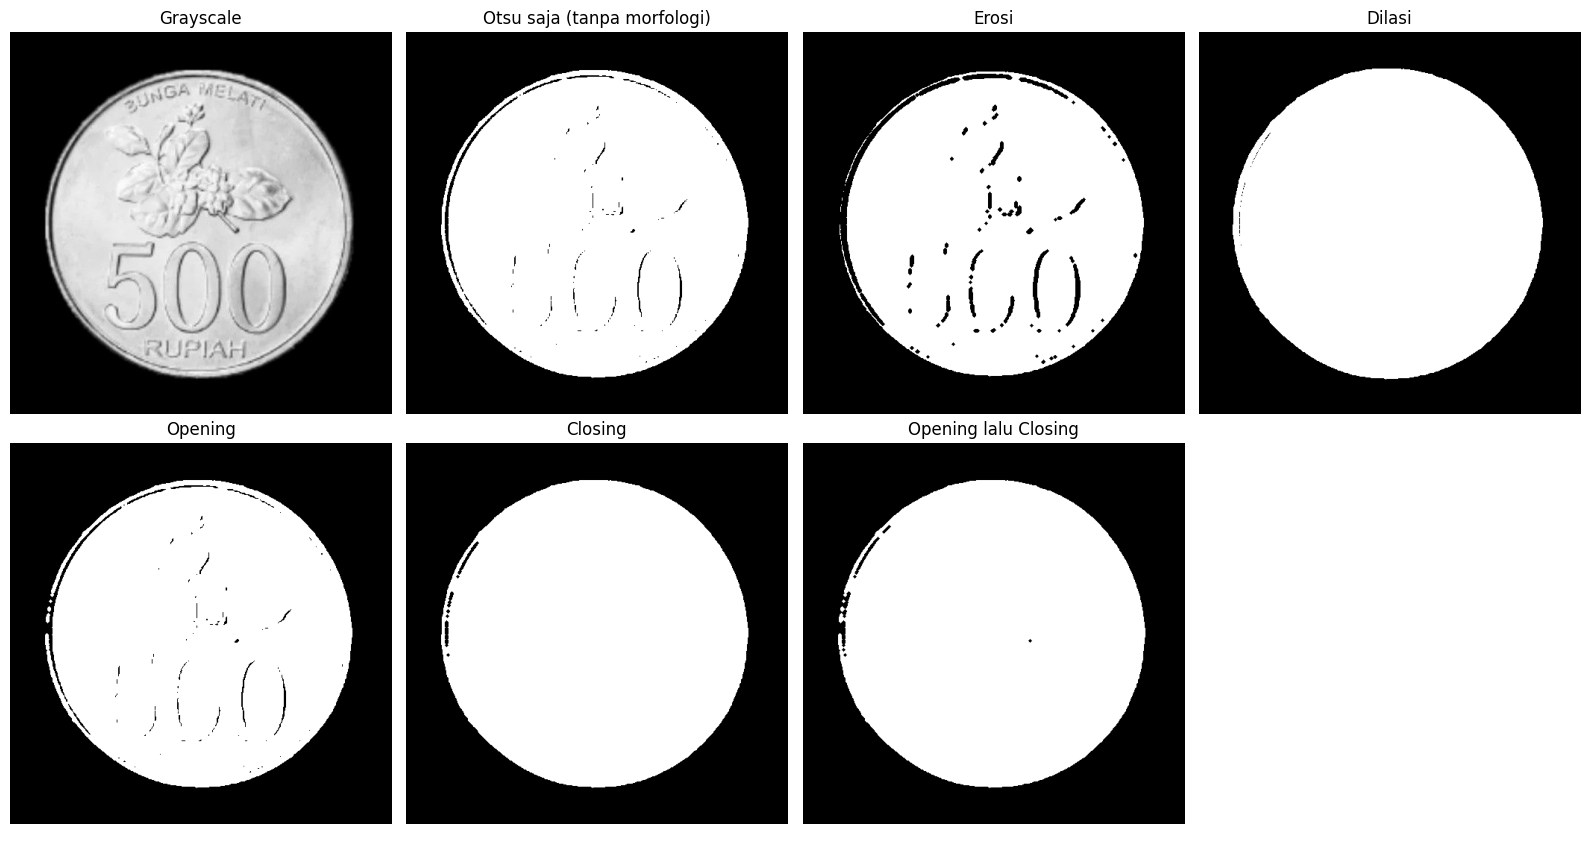

Metode                         Luas objek (px)
Otsu saja (tanpa morfologi)             130551
Erosi                                   123348
Dilasi                                  135192
Opening                                 130337
Closing                                 132421
Opening lalu Closing                    132153


In [14]:
proses_citra(DATASET[1])

Apel | T Otsu = 160 | SE lingkaran radius 2


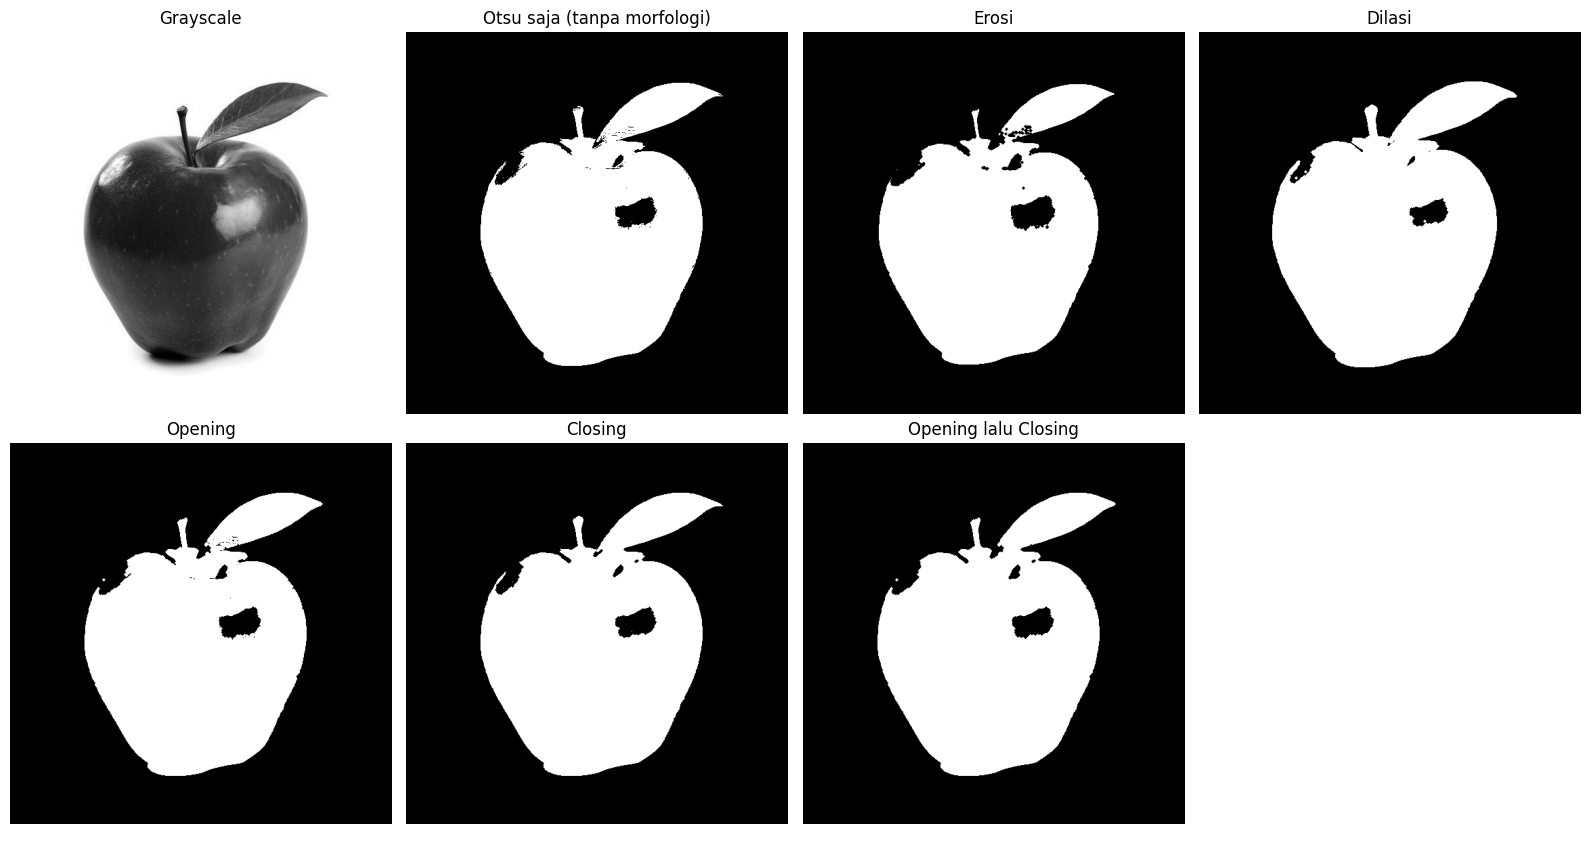

Metode                         Luas objek (px)
Otsu saja (tanpa morfologi)              91055
Erosi                                    86615
Dilasi                                   94973
Opening                                  90575
Closing                                  91467
Opening lalu Closing                     90759


In [15]:
proses_citra(DATASET[2])